# 온라인 쇼핑몰에서 다시 구매하는 고객은 누구인가?
AdventureWorks의 온라인 주문 전체를 사용해 재구매 고객을 찾고, 첫 구매 후 돌아오지 않은 고객과 비교한다. 구매 분석의 단위는 고객, 이미지 분석의 단위는 고유 상품 사진이다. 금액은 원본의 세금·배송비 제외 상품 소계 단위다.

## 1. 거래 구조와 분석 기간
거래 한 행은 한 주문의 한 상품 내역이다. 고객 수, 주문 수, 구매 상품 수를 분리해 세고 원본의 열별 자료형과 분포를 먼저 확인한다.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

root = Path.cwd()
if not (root / "data" / "transactions.csv").is_file():
    root = root.parent
sys.path.insert(0, str(root))
from src.pipeline import DataAnalyzer

sns.set_theme(style="whitegrid", context="notebook")
analyzer = DataAnalyzer(root / "data" / "transactions.csv")
df = analyzer.load_data()
df.info()
display(df.head(), df.describe())
display(df[["customer_id", "order_id", "product_id", "image_path"]].nunique())
print(df["order_date"].min().date(), df["order_date"].max().date())

<class 'pandas.DataFrame'>
RangeIndex: 60398 entries, 0 to 60397
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customer_id       60398 non-null  string        
 1   order_id          60398 non-null  string        
 2   order_date        60398 non-null  datetime64[us]
 3   product_id        60398 non-null  string        
 4   product_name      60398 non-null  str           
 5   product_category  60398 non-null  str           
 6   quantity          60398 non-null  int64         
 7   unit_price        60398 non-null  float64       
 8   discount_rate     60398 non-null  float64       
 9   line_amount       60398 non-null  float64       
 10  image_path        31966 non-null  str           
dtypes: datetime64[us](1), float64(3), int64(1), str(3), string(3)
memory usage: 5.1 MB


,customer_id,order_id,order_date,product_id,product_name,product_category,quantity,unit_price,discount_rate,line_amount,image_path
0,21768,43697,2022-05-30,749,"Road-150 Red, 62",Bikes,1,3578.2700,0.0,3578.2700,images/126_superlight_red_large.gif
1,28389,43698,2022-05-30,773,"Mountain-100 Silver, 44",Bikes,1,3399.9900,0.0,3399.9900,images/128_superlight_silver_large.gif
2,25863,43699,2022-05-30,773,"Mountain-100 Silver, 44",Bikes,1,3399.9900,0.0,3399.9900,images/128_superlight_silver_large.gif
3,14501,43700,2022-05-30,767,"Road-650 Black, 62",Bikes,1,699.0982,0.0,699.0982,images/118_superlight_black_large.gif
4,11003,43701,2022-05-30,773,"Mountain-100 Silver, 44",Bikes,1,3399.9900,0.0,3399.9900,images/128_superlight_silver_large.gif


,order_date,quantity,unit_price,discount_rate,line_amount
count,60398,60398.0,60398.000000,60398.0,60398.000000
mean,2024-11-08 12:21:38.903937,1.0,486.086911,0.0,486.086911
min,2022-05-30 00:00:00,1.0,2.290000,0.0,2.290000
25%,2024-09-02 00:00:00,1.0,7.950000,0.0,7.950000
50%,2024-12-13 00:00:00,1.0,29.990000,0.0,29.990000
75%,2025-03-19 00:00:00,1.0,539.990000,0.0,539.990000
max,2025-06-29 00:00:00,1.0,3578.270000,0.0,3578.270000
std,NaN,0.0,928.489892,0.0,928.489892


customer_id    18484
order_id       27659
product_id       130
image_path        22
dtype: int64

2022-05-30 2025-06-29


60,398개 상품 내역(11열)은 27,659개 주문과 18,484명 고객에 속한다. 주문 하나에 여러 상품이 있을 수 있으므로 구매 빈도는 고객별 고유 주문번호 수로 계산한다. 수량은 모두 1이고 할인율은 모두 0이므로 두 변수의 상관계수는 해석할 수 없다. 고객별 마지막 구매 후 경과일과 누적 금액은 서로 다른 구매 패턴을 비교하는 데 사용할 수 있다.

## 2. 상품명과 이미지 피처
상품명은 공백을 포함한 글자 수로 변환한다. 각 GIF의 전체 RGB 채널값(0~255)에서 평균·모집단 표준편차를 구한다. 채널값의 3구간 히스토그램 비율은 어두운 값, 중간 값, 밝은 값의 상대 빈도다. 같은 사진은 한 번만 읽고, 서로 다른 이미지 크기는 계산에서 제외되는 NaN으로 패딩한다.

In [2]:
df = analyzer.add_features()
hist_columns = ["dark_share", "mid_share", "bright_share"]
image_columns = ["pixel_mean", "pixel_std", *hist_columns]
photos = df.dropna(subset=["image_path"]).drop_duplicates("image_path")
display(photos[["product_name", "name_length", "image_path", *image_columns]].head())
display(photos.groupby("product_category")[image_columns].mean().round(3))
assert np.allclose(photos[hist_columns].sum(axis=1), 1)

,product_name,name_length,image_path,pixel_mean,pixel_std,dark_share,mid_share,bright_share
0,"Road-150 Red, 62",16,images/126_superlight_red_large.gif,217.485825,70.516541,0.075112,0.128533,0.796355
1,"Mountain-100 Silver, 44",23,images/128_superlight_silver_large.gif,223.743042,58.655289,0.039821,0.138712,0.821467
3,"Road-650 Black, 62",18,images/118_superlight_black_large.gif,216.262421,70.633789,0.074142,0.139262,0.786596
2206,"Road-550-W Yellow, 42",21,images/131_racer02_yellow_f_large.gif,217.812256,66.796051,0.070610,0.128179,0.801212
2207,"Road-250 Red, 58",16,images/179_racer_red_large.gif,214.195602,70.210983,0.079036,0.140082,0.780882


,pixel_mean,pixel_std,dark_share,mid_share,bright_share
product_category,,,,,
Accessories,206.835999,64.595001,0.073,0.194,0.733
Bikes,215.104004,71.559998,0.081,0.131,0.788
Clothing,187.578995,74.041000,0.111,0.288,0.601


22장의 사진이 31,966개 거래 행에 연결된다. 같은 사진을 주문 횟수만큼 반복해서 세면 자주 팔린 상품의 색이 평균을 좌우하므로 사진의 통계는 고유 경로별로 집계한다. 배경까지 포함한 채널 분포이므로 밝은 값의 비율은 제품 표면의 색상 비율과 다를 수 있다.

## 3. 결측치와 대분류별 대치
관측된 고유 사진의 대분류별 중앙값을 계산해 사진이 없는 행의 분석용 평균·표준편차를 채운다. 원본 사진 경로와 관측 피처는 보존하고 추정 피처 및 결측 표시를 별도 열에 둔다.

In [3]:
missing_before = df.isna().sum().rename("missing_before")
df = analyzer.handle_missing_values(group_col="product_category", strategy="median")
display(missing_before.to_frame())
display(df.groupby("product_category").agg(
    unique_photos=("image_path", "nunique"), missing_rows=("image_missing", "sum"),
    remaining_missing=("pixel_mean_filled", lambda x: x.isna().sum()),
))
display(df.loc[df["image_missing"], [
    "product_name", "product_category", "image_missing", "pixel_mean", "pixel_mean_filled"
]].head())

,missing_before
customer_id,0
order_id,0
order_date,0
product_id,0
product_name,0
product_category,0
quantity,0
unit_price,0
discount_rate,0
line_amount,0


,unique_photos,missing_rows,remaining_missing
product_category,,,
Accessories,6,23203,0
Bikes,13,479,0
Clothing,3,4750,0


,product_name,product_category,image_missing,pixel_mean,pixel_mean_filled
5431,"Sport-100 Helmet, Black",Accessories,True,NaN,207.006485
5433,Mountain Bottle Cage,Accessories,True,NaN,207.006485
5437,Road Tire Tube,Accessories,True,NaN,207.006485
5438,All-Purpose Bike Stand,Accessories,True,NaN,207.006485
5442,"Sport-100 Helmet, Red",Accessories,True,NaN,207.006485


28,432개 행에는 원본 사진이 없다. 대분류별 사진 수는 자전거 13장, 액세서리 6장, 의류 3장이라서 모두 그룹 중앙값을 계산할 수 있다. 특히 의류의 3장으로 추정한 값은 개별 상품의 색상을 설명하기 어렵다. 사진 유무는 RFM에서 거래를 제외하는 기준으로 사용하지 않는다.

## 4. 고객별 RFM과 구매액 분포
기준일은 관측된 마지막 거래일인 2025-06-29이다. R은 마지막 구매일부터 기준일까지의 일수, F는 고유 주문 수, M은 할인 후 상품 금액의 합계다. 원자료를 보존한 상태에서 IQR 경계 밖의 누적 구매액만 시각화용 사본에서 경계값으로 제한한다.

,count,mean,std,min,25%,50%,75%,max
recency,18484.0,189.332,146.289,0.00,86.00,168.000,263.000,1126.00
frequency,18484.0,1.496,1.101,1.00,1.00,1.000,2.000,28.00
monetary,18484.0,1588.329,2124.232,2.29,49.97,270.265,2511.275,13295.38


IQR 경계 -3,641.99 ~ 6,203.23 / 이상치 677명


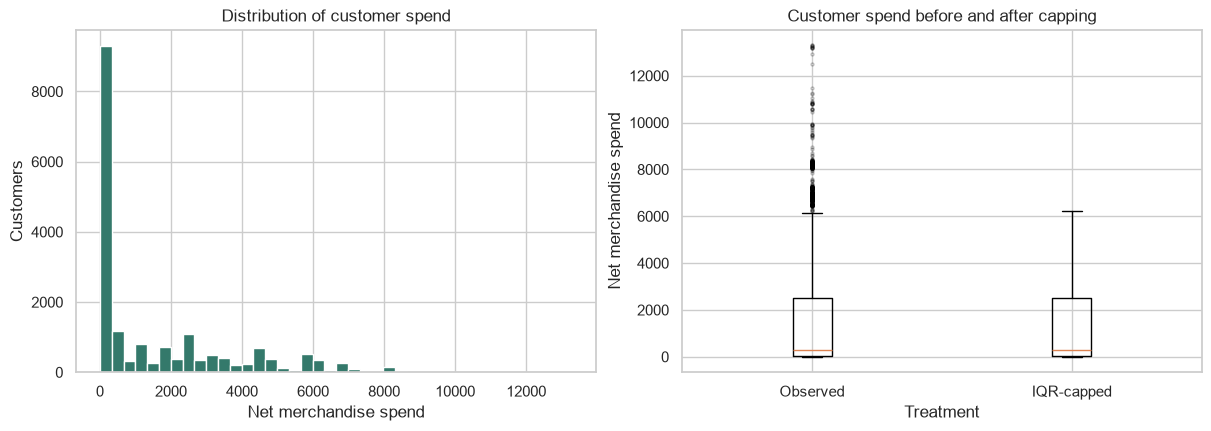

In [4]:
rfm = analyzer.calculate_rfm()
measures = ["recency", "frequency", "monetary"]
display(analyzer.summarize(rfm, measures).round(3))
flags, lower, upper = analyzer.detect_outliers(rfm["monetary"], multiplier=1.5)
capped = rfm["monetary"].clip(lower=lower, upper=upper)
print(f"IQR 경계 {lower:,.2f} ~ {upper:,.2f} / 이상치 {flags.sum():,}명")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
axes[0].hist(rfm["monetary"], bins=40, color="#34796b")
axes[0].set(title="Distribution of customer spend", xlabel="Net merchandise spend", ylabel="Customers")
axes[1].boxplot([rfm["monetary"], capped], showfliers=True,
                flierprops={"markersize": 2, "alpha": .25})
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["Observed", "IQR-capped"])
axes[1].set(title="Customer spend before and after capping", xlabel="Treatment", ylabel="Net merchandise spend")
plt.show()

고객당 누적 구매액은 평균 1,588.33, 중앙값 270.27로 고액 구매자가 평균을 끌어올린다. 누적 구매액의 표본 표준편차는 2,124.23으로 평균보다 크다. 고객별 지출 차이가 커서 대표 고객의 지출 수준은 중앙값과 함께 살펴야 한다. 중앙 50%는 약 49.97~2,511.28 사이이며 IQR 경계를 넘는 고객은 677명이다. 상위 고객을 이상 거래로 단정하면 단골 분석이 왜곡되므로 세분화와 매출 집계에는 원래 금액을 쓴다.

## 5. 구매 빈도·최근성·금액의 관계
고객 단위 피어슨 상관행렬과 최근성–구매액 산점도를 함께 살펴본다. 최근성 값이 클수록 마지막 구매 후 더 오래 지난 고객이다.

,recency,frequency,monetary
recency,1.0000,-0.1582,0.0740
frequency,-0.1582,1.0000,0.3817
monetary,0.0740,0.3817,1.0000


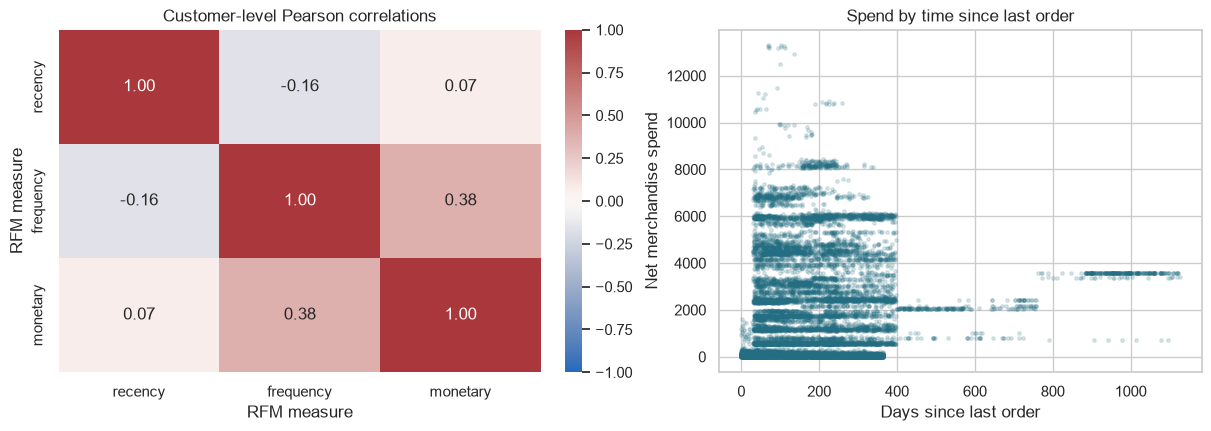

In [5]:
corr = rfm[measures].corr()
display(corr.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
sns.heatmap(corr, vmin=-1, vmax=1, center=0, cmap="vlag", annot=True, fmt=".2f", ax=axes[0])
axes[0].set(title="Customer-level Pearson correlations", xlabel="RFM measure", ylabel="RFM measure")
axes[1].scatter(rfm["recency"], rfm["monetary"], s=6, alpha=.16, color="#236e82")
axes[1].set(title="Spend by time since last order", xlabel="Days since last order", ylabel="Net merchandise spend")
plt.show()

최근성과 주문 횟수의 상관계수는 −0.158로, 자주 주문한 고객이 조금 더 최근에 구매하는 경향이 있다. 최근성과 누적 구매액의 상관은 +0.074로 약하다. 마지막 구매일만으로 고액 고객을 찾기 어려우므로 금액과 구매 빈도를 함께 반영한다.

## 6. RFM 점수와 세그먼트
R은 중앙값 168일 이내이면 2점, 나머지는 1점이다. F는 1회·2회·3회 이상을 각각 1·2·3점으로 둔다. M은 누적 금액이 고객 중앙값 이상이면 2점, 미만이면 1점이다. 구매 횟수 동점을 보존하기 위해 동일 인원수의 분위수로 강제 분할하지 않는다.

재구매 고객은 M으로 고액·저액을, 1회 구매 고객은 R로 최근·장기 미구매를 구분한다. '최근'과 '고액'은 이 표본 기준이며 예측 확률이나 확정 이탈 판정이 아니다.

,recency,frequency,monetary,r_score,f_score,m_score,segment
customer_id,,,,,,,
11000,270,3,8248.99,1,3,2,High-value repeat
11001,49,3,6383.88,2,3,2,High-value repeat
11002,339,3,8114.04,1,3,2,High-value repeat
11003,263,3,8139.29,1,3,2,High-value repeat
11004,272,3,8196.01,1,3,2,High-value repeat


,customers,avg_recency,avg_frequency,avg_spend,total_spend,sales_pct
segment,,,,,,
Older single,6366,308.79,1.00,637.81,4060288.48,13.83
Recent single,5253,87.83,1.00,511.65,2687677.02,9.15
High-value repeat,5114,170.62,2.36,4382.46,22411895.05,76.34
Lower-value repeat,1751,114.19,2.26,113.54,198816.67,0.68


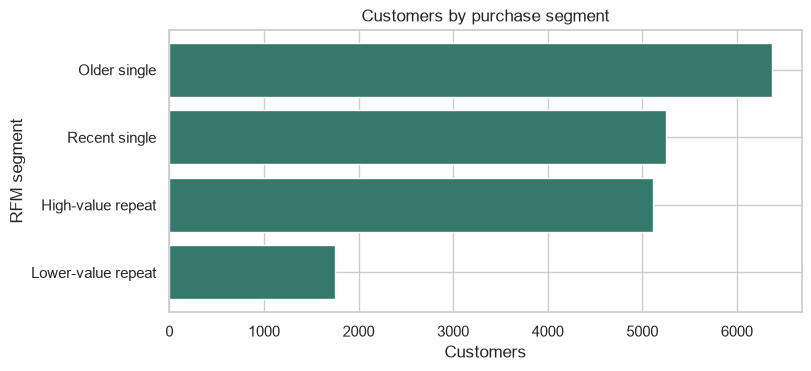

In [6]:
display(rfm[measures + ["r_score", "f_score", "m_score", "segment"]].head())
groups = rfm.groupby("segment").agg(
    customers=("monetary", "size"), avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"), avg_spend=("monetary", "mean"),
    total_spend=("monetary", "sum"),
).sort_values("customers", ascending=False)
groups["sales_pct"] = 100 * groups["total_spend"] / groups["total_spend"].sum()
display(groups.round(2))
fig, ax = plt.subplots(figsize=(8, 3.6), constrained_layout=True)
ax.barh(groups.index, groups["customers"], color="#34796b")
ax.invert_yaxis()
ax.set(title="Customers by purchase segment", xlabel="Customers", ylabel="RFM segment")
plt.show()

고액 재구매 고객 5,114명이 전체 상품 매출의 약 76.3%를 차지한다. 이 고객군에는 무차별 할인보다 기존 단골을 유지하는 실험이 적합하다. 최근 1회 고객 5,253명은 두 번째 구매를 유도할 대상이며, 장기 미구매 1회 고객 6,366명은 평균 마지막 구매 후 약 309일이 지나 재활성화 효과를 별도로 검증할 대상이다. 구체적인 검증 지표와 필요한 데이터는 README 결과물의 인사이트 문서에 정리한다.

## 7. 월별 매출 추이
주문 상품 금액을 달력 월별로 합산한다. 첫 달과 마지막 달은 관측 기간이 한 달 전체를 포함하지 않으므로 인접 월과 비교할 때 기간 길이를 고려한다.

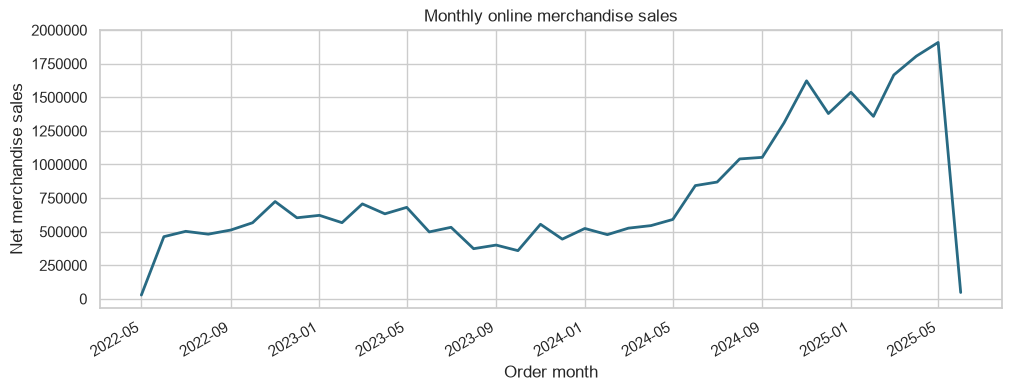

월별 매출 최고점: 2025-05, 1,908,059.49


In [7]:
monthly = df.groupby(df["order_date"].dt.to_period("M"))["line_amount"].sum()
fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
ax.plot(monthly.index.to_timestamp(), monthly, color="#286a83", linewidth=2)
ax.ticklabel_format(axis="y", style="plain")
ax.set(title="Monthly online merchandise sales", xlabel="Order month", ylabel="Net merchandise sales")
fig.autofmt_xdate()
plt.show()
print(f"월별 매출 최고점: {monthly.idxmax()}, {monthly.max():,.2f}")

38개 관측 월 중 2025년 5월의 매출이 약 190.8만으로 가장 높다. 첫 달은 2022년 5월 30일부터, 마지막 달은 2025년 6월 29일까지 집계되므로 경계 월의 급변을 그대로 수요 증감으로 해석하기 어렵다.

## 8. 첫 온라인 구매월별 재구매
가입일은 제공되지 않아 고객별 **첫 관측 온라인 구매월**로 코호트를 정한다. M0은 코호트 고객 전체(100%)다. M1 이후 각 칸은 해당 월에 한 번 이상 구매한 고유 고객 수를 M0 고객 수로 나눈 값이다. 중간에 쉬었다가 돌아온 고객도 그 달의 분자에 포함된다.

관측이 끝난 달까지 구매가 없으면 0%, 아직 해당 월에 도달하지 않은 칸은 결측으로 구분한다. 2022년 5월은 30일부터의 짧은 유입 기간이고, 2025년 6월에 해당하는 값은 29일까지만 관측한 잠정치다.

In [8]:
cohort_counts, retention = analyzer.purchase_cohorts()
last_month = df["order_date"].max().to_period("M")
display(cohort_counts.iloc[:, :4].rename(columns=lambda age: f"M{age}").astype("Int64"))
assert cohort_counts[0].sum() == len(rfm)
assert retention[0].eq(1).all()

# M1을 관측할 수 있는 코호트의 합산 구매자 수와 기준 인원
m1 = cohort_counts[[0, 1]].dropna()
m1_end = (m1.index + 1).to_timestamp(how="end").normalize()
full_m1 = m1.loc[m1_end <= df["order_date"].max()]
weighted = pd.DataFrame({
    "부분월 포함": m1.sum(),
    "온전한 M1만": full_m1.sum(),
}).T.astype(int).rename(columns={0: "기준 인원", 1: "M1 구매자"})
weighted["M1 재구매율(%)"] = 100 * weighted["M1 구매자"] / weighted["기준 인원"]
display(weighted.round(2))

example = pd.Period("2024-06", freq="M")
display(pd.DataFrame({
    "구매자": cohort_counts.loc[example, [0, 1, 2]].astype(int),
    "비율(%)": 100 * retention.loc[example, [0, 1, 2]],
}).rename(index=lambda age: f"M{age}").round(2))

age,M0,M1,M2,M3
cohort,,,,
2022-05,9,0,0,0
2022-06,142,0,0,0
2022-07,155,0,0,0
2022-08,149,0,0,0
2022-09,160,0,0,0
2022-10,176,0,0,0
2022-11,227,0,0,0
2022-12,189,0,0,0
2023-01,195,0,0,0


age,기준 인원,M1 구매자,M1 재구매율(%)
부분월 포함,17960,346,1.93
온전한 M1만,16802,329,1.96


,구매자,비율(%)
age,,
M0,262,100.00
M1,11,4.20
M2,7,2.67


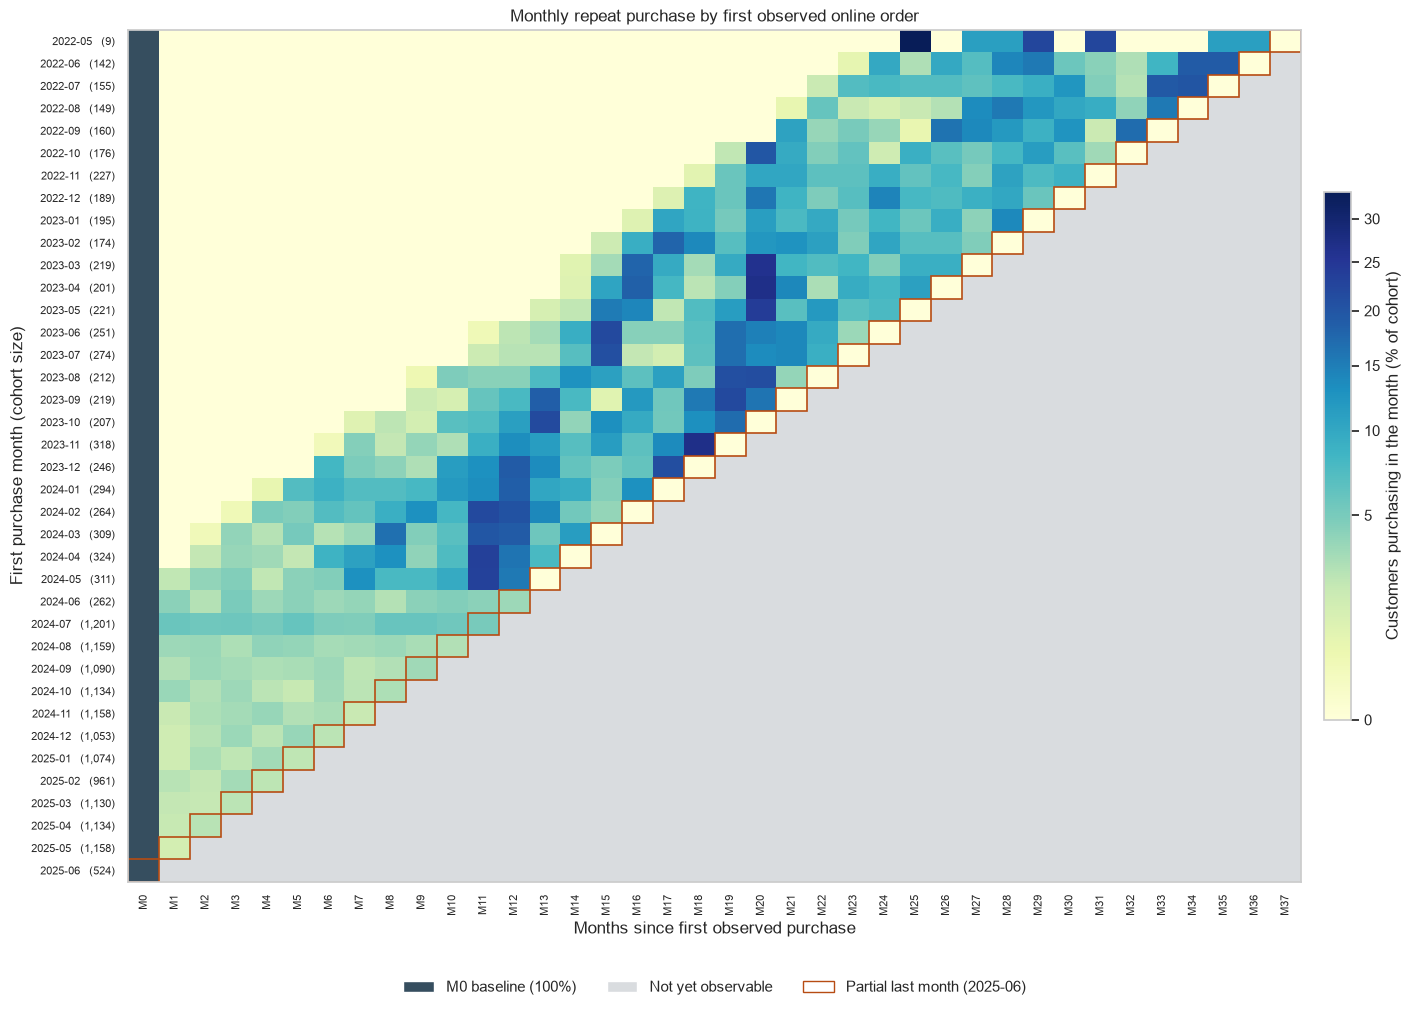

In [9]:
from matplotlib.colors import PowerNorm
from matplotlib.patches import Patch, Rectangle

# M0 기준열과 M1 이후 재구매율 색상 분리
percent = 100 * retention
ages = percent.columns.to_numpy()
fig, ax = plt.subplots(figsize=(14, 10), constrained_layout=True)
cohort_colors = plt.get_cmap("YlGnBu").copy()
cohort_colors.set_bad("#d9dcdf")
values = percent.to_numpy().copy()
values[:, 0] = np.nan
heat = ax.imshow(values, cmap=cohort_colors, norm=PowerNorm(.5, vmin=0, vmax=np.nanmax(values)),
                 aspect="auto", interpolation="nearest")
ax.axvspan(-.5, .5, color="#364e5f", linewidth=0)
ax.set_xticks(ages)
ax.set_xticklabels([f"M{i}" for i in ages], fontsize=8, rotation=90)
ax.set_yticks(range(len(percent)))
ax.set_yticklabels([f"{month}   ({int(size):,})" for month, size in cohort_counts[0].items()], fontsize=8)
ax.grid(False)
ax.set(title="Monthly repeat purchase by first observed online order",
       xlabel="Months since first observed purchase", ylabel="First purchase month (cohort size)")
bar = fig.colorbar(heat, ax=ax, shrink=.62, pad=.02)
bar.set_label("Customers purchasing in the month (% of cohort)")
# 마지막 관측월 잠정치 테두리
for row, month in enumerate(percent.index):
    last_age = last_month.ordinal - month.ordinal
    ax.add_patch(Rectangle((last_age - .5, row - .5), 1, 1, fill=False,
                           edgecolor="#b74c13", linewidth=1.2))
ax.legend(handles=[
    Patch(facecolor="#364e5f", label="M0 baseline (100%)"),
    Patch(facecolor="#d9dcdf", label="Not yet observable"),
    Patch(facecolor="none", edgecolor="#b74c13", label=f"Partial last month ({last_month})"),
], loc="upper center", bbox_to_anchor=(.5, -.10), ncol=3, frameon=False)
figure_path = root / "docs" / "cohort-heatmap.png"
figure_path.parent.mkdir(exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

2025년 1월에 처음 구매한 1,074명 가운데 2월(M1)에 18명(1.68%), 3월(M2)에 32명(2.98%)이 구매했다. 서로 다른 달의 구매자를 더하면 중복될 수 있으므로 각 달의 재방문 규모를 개별적으로 읽는다. 2025년 6월에 처음 관측된 고객 524명은 다음 달 데이터가 없어 M1을 아직 평가할 수 없다. 최근 코호트의 성과를 비교할 때는 같은 경과월까지 관측된 집단만 비교한다.

## 9. 선택 과제 · 고객군 탐색
점 하나가 한 고객군을 나타낸다. 가로축은 평균 최근성, 세로축은 평균 누적 구매액, 원 크기는 고객 수다. 점에 마우스를 올려 구매 빈도와 매출 비중을 확인한다. 가입일은 제공되지 않아 가입 월별 코호트 유지율은 산출하지 않는다.

In [10]:
import plotly.express as px

interactive = px.scatter(
    groups.reset_index(), x="avg_recency", y="avg_spend", size="customers", color="segment",
    hover_name="segment", hover_data={"avg_frequency": ":.2f", "sales_pct": ":.1f", "customers": ":,"},
    labels={"avg_recency": "Average days since last order", "avg_spend": "Average net spend",
            "customers": "Customers", "avg_frequency": "Mean orders", "sales_pct": "Sales share (%)"},
    title="Online customer segments", size_max=48,
)
target = root / "docs" / "segments.html"
target.parent.mkdir(exist_ok=True)
interactive.write_html(target, include_plotlyjs=True, auto_open=False)
print(target.relative_to(root))

docs/segments.html
